# Pump It Up: Problem Exploration

This notebook documents the exploratory analysis, data quality review, and modeling decisions for the portfolio project.

## 1. Contexto y objetivo

The organization needs to prioritize maintenance for water points. The objective is to classify each pump as `functional`, `non functional`, or `functional needs repair`, with special attention to the minority class.

This notebook focuses on understanding the data and documenting decisions; reusable preprocessing lives in `src/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = None
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "src").is_dir() and (candidate / "data").is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing src/ and data/.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_pump_it_up_data
from src.eda import column_type_summary, missingness_summary, target_distribution

DATA_DIR = PROJECT_ROOT / "data"
train_values, train_labels, test_values = load_pump_it_up_data(DATA_DIR)
train = train_values.merge(train_labels, on="id", validate="one_to_one")

print(f"Train values: {train_values.shape}")
print(f"Train labels: {train_labels.shape}")
print(f"Test values: {test_values.shape}")
train.head()

Train values: (59400, 40)
Train labels: (59400, 2)
Test values: (14850, 40)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


## 2. Data quality

We first quantify missing values. Missingness patterns will guide decisions about dropping columns, imputation, and category grouping.

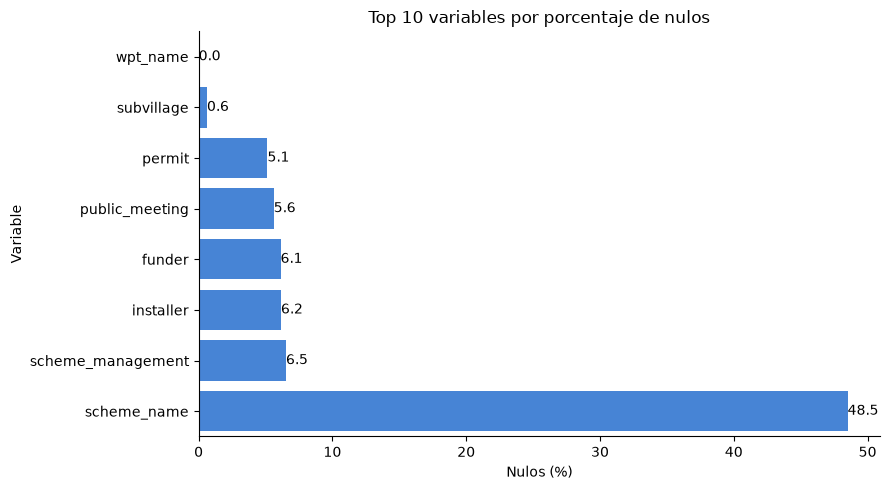

In [2]:
missing = missingness_summary(train).head(10).sort_values("missing_pct")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=missing.reset_index(), x="missing_pct", y="index", color="#2f80ed", ax=ax)
ax.set(title="Top 10 features by missing-value percentage", xlabel="Missing values (%)", ylabel="Feature")
ax.bar_label(ax.containers[0], fmt="%.1f")
sns.despine()
plt.tight_layout()
plt.show()

## 3. Target distribution

The `functional needs repair` class is the minority class. Accuracy alone is therefore not enough to evaluate the model: we will also use macro F1, per-class recall, and the confusion matrix.

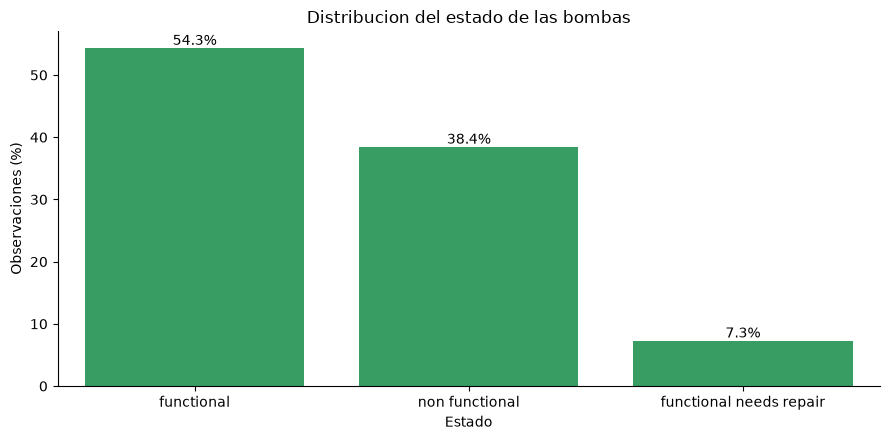

In [3]:
target_summary = target_distribution(train).reset_index(names="status_group")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=target_summary, x="status_group", y="percentage", color="#27ae60", ax=ax)
ax.set(title="Pump condition distribution", xlabel="Condition", ylabel="Observations (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
sns.despine()
plt.tight_layout()
plt.show()

## 4. Categorical feature cardinality

High-cardinality features may contain useful signal but can also increase overfitting risk. This summary will inform decisions about dropping features, rare grouping, or frequency encoding.

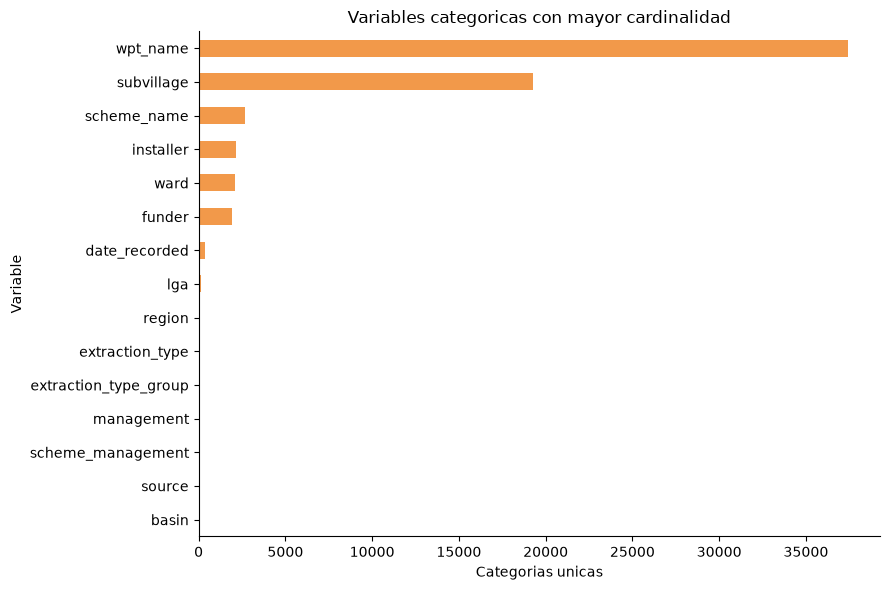

In [4]:
categorical = column_type_summary(train).query("column_type == 'categorical'").index
cardinality = train[categorical].nunique().sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
cardinality.sort_values().plot.barh(ax=ax, color="#f2994a")
ax.set(title="Highest-cardinality categorical features", xlabel="Unique categories", ylabel="Feature")
sns.despine()
plt.tight_layout()
plt.show()